In [1]:
import torch
import os
import logging
import timm
import pandas as pd
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
from src.dataset import FundusDataset, get_transform, get_soft_balanced_sampler
from src.loss import FocalLoss
from src.model import EfficientNetB4_CBAM
from src.optimizer import optimizer, optimizer_update
from src.training import training

def seed(seed):
    import random
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed(1)

g = torch.Generator()
g.manual_seed(1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data_dir = "D:/DeepLearning/Dataset/APTOS-2019"
train_img_dir = os.path.join(data_dir, "train_images")
valid_img_dir = os.path.join(data_dir, "valid_images")
test_img_dir = os.path.join(data_dir, "test_images")
train_csv_dir = os.path.join(data_dir, "train.csv")
valid_csv_dir = os.path.join(data_dir, "valid.csv")
test_csv_dir = os.path.join(data_dir, "test.csv")
eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/APTOS-2019"
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
log_dir = os.path.join(eval_dir, "logs")

train_df = pd.read_csv(train_csv_dir)
valid_df = pd.read_csv(valid_csv_dir)
train_df['diagnosis'] = train_df['diagnosis'].astype(int)
valid_df['diagnosis'] = valid_df['diagnosis'].astype(int)

train_transform, valid_transform = get_transform(380)

train_dataset = FundusDataset(train_df, img_dir=train_img_dir, transform=train_transform)
valid_dataset = FundusDataset(valid_df, img_dir=valid_img_dir, transform=valid_transform)

sampler, class_weights = get_soft_balanced_sampler(train_df, softness=0) # softness=0 means perfect class balance

train_loader = DataLoader(
    train_dataset,
    batch_size=48,
    sampler=sampler,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    prefetch_factor=2,
    generator=g,
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=48,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    prefetch_factor=2,
    generator=g,
)

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
model = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.3, classifier_dropout_rate=0.5, num_class=5)
model.freeze(block_index=4, freeze_stem=True)
model = model.to(device)

alpha_raw = torch.tensor([class_weights[i] for i in sorted(class_weights.keys())], dtype=torch.float)
alpha_smooth = torch.sqrt(alpha_raw)
alpha_tensor = alpha_smooth / alpha_smooth.mean() # normalise with mean so that tensor's average is 1
alpha_tensor = alpha_tensor.to(device)
criterion = FocalLoss(alpha=alpha_tensor, gamma=2)

# checkpoint = torch.load(os.path.join(chkpt_dir, "epoch30_validF1_0.7592.pth"))
# model.load_state_dict(checkpoint["model_state"])
# optimizer.load_state_dict(checkpoint["optimizer_state"])
# scheduler.load_state_dict(checkpoint["scheduler_state"])
# start_epoch = checkpoint["epoch"]
# best_validation_f1 = checkpoint["best_valid_f1"]

for handler in logging.root.handlers[:]:
    logging.root.removeHandler(handler)

log_file = os.path.join(log_dir, 'training_log_gradual_unfreezing.txt')
logging.basicConfig(
    filename=log_file,
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    filemode='a'  # use 'a' to append to existing logs
)

best_checkpoint_path = os.path.join(chkpt_dir, "best_checkpoint.pth")
training_record = {
        "train_loss": [],
        "valid_loss": [],
        "train_f1": [],
        "valid_f1": [],
    }

optimizer = optimizer(model=model, lr=5e-4, weight_decay=1e-4)
scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=20, T_mult=1, eta_min=1e-6)

training_record = training(model, train_loader, valid_loader, criterion, optimizer, scheduler, device, chkpt_dir, training_record, num_epochs=20, best_validation_f1=-1.0, start_epoch=0)

model.unfreeze(block_index=4, unfreeze_stem=False)
checkpoint = torch.load(best_checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["model_state"])
best_validation_f1 = checkpoint["best_valid_f1"]
optimizer = optimizer_update(optimizer=optimizer, model=model, lr=1e-4, weight_decay=1e-4)
scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=30, T_mult=1, eta_min=1e-6)

training_record = training(model, train_loader, valid_loader, criterion, optimizer, scheduler, device, chkpt_dir, training_record, num_epochs=50, best_validation_f1=best_validation_f1, start_epoch=20)

model.unfreeze(block_index=3, unfreeze_stem=False)
checkpoint = torch.load(best_checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["model_state"])
best_validation_f1 = checkpoint["best_valid_f1"]
optimizer = optimizer_update(optimizer=optimizer, model=model, lr=1e-5, weight_decay=1e-4)
scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=30, T_mult=1, eta_min=1e-7)

training_record = training(model, train_loader, valid_loader, criterion, optimizer, scheduler, device, chkpt_dir, training_record, num_epochs=80, best_validation_f1=best_validation_f1, start_epoch=50)

# model.unfreeze(block_index=2, unfreeze_stem=False)
# model.unfreeze(block_index=1, unfreeze_stem=False)
# model.unfreeze(block_index=0, unfreeze_stem=True)
# checkpoint = torch.load(best_checkpoint_path, map_location=device)
# model.load_state_dict(checkpoint["model_state"])
# best_validation_f1 = checkpoint["best_valid_f1"]
# optimizer = optimizer_update(optimizer=optimizer, model=model, lr=1e-6, weight_decay=1e-4)
# scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=30, T_mult=1, eta_min=1e-7)
#
# training_record = training(model, train_loader, valid_loader, criterion, optimizer, scheduler, device, chkpt_dir, training_record, num_epochs=140, best_validation_f1=best_validation_f1, start_epoch=110)

Training: Epoch 1/20:   0%|          | 0/62 [00:00<?, ?it/s]

Validation::   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 1/20:
Train Loss: 0.7968, Train Accuracy: 0.3491, Train F1: 0.3200
Valid Loss: 0.4283, Valid Accuracy: 0.5820, Valid F1: 0.3839
best model saved to:  D:/DeepLearning/Evaluation/EfficientNet-B4/APTOS-2019\checkpointspaper\epoch1_validF1_0.3839.pth


Training: Epoch 2/20:   0%|          | 0/62 [00:00<?, ?it/s]

Validation::   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 2/20:
Train Loss: 0.5321, Train Accuracy: 0.5474, Train F1: 0.5202
Valid Loss: 0.3459, Valid Accuracy: 0.6639, Valid F1: 0.4944
best model saved to:  D:/DeepLearning/Evaluation/EfficientNet-B4/APTOS-2019\checkpointspaper\epoch2_validF1_0.4944.pth


... (230 outputs left out)

Epoch 79/80:
Train Loss: 0.0394, Train Accuracy: 0.9532, Train F1: 0.9539
Valid Loss: 0.4141, Valid Accuracy: 0.8224, Valid F1: 0.6789


Training: Epoch 80/80:   0%|          | 0/62 [00:00<?, ?it/s]

Validation::   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 80/80:
Train Loss: 0.0283, Train Accuracy: 0.9614, Train F1: 0.9619
Valid Loss: 0.4269, Valid Accuracy: 0.8333, Valid F1: 0.7039


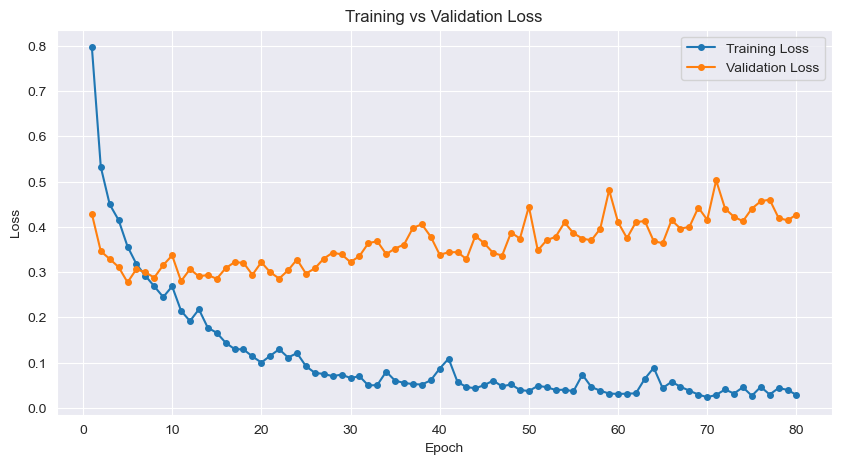

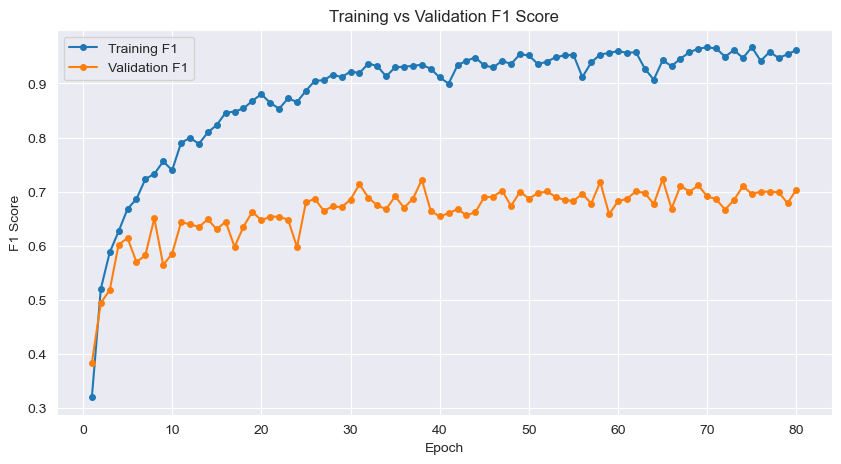

In [2]:
import matplotlib.pyplot as plt

epochs = range(1, len(training_record["train_loss"]) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs, training_record["train_loss"], label="Training Loss", marker='o', markersize=4)
plt.plot(epochs, training_record["valid_loss"], label="Validation Loss", marker='o', markersize=4)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(epochs, training_record["train_f1"], label="Training F1", marker='o', markersize=4)
plt.plot(epochs, training_record["valid_f1"], label="Validation F1", marker='o', markersize=4)
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("Training vs Validation F1 Score")
plt.legend()
plt.grid(True)
plt.show()

{'0': {'precision': 0.98, 'recall': 0.9849246231155779, 'f1-score': 0.9824561403508771, 'support': 199.0}, '1': {'precision': 0.6129032258064516, 'recall': 0.6333333333333333, 'f1-score': 0.6229508196721312, 'support': 30.0}, '2': {'precision': 0.7070707070707071, 'recall': 0.8045977011494253, 'f1-score': 0.7526881720430108, 'support': 87.0}, '3': {'precision': 0.3333333333333333, 'recall': 0.4117647058823529, 'f1-score': 0.3684210526315789, 'support': 17.0}, '4': {'precision': 0.8666666666666667, 'recall': 0.3939393939393939, 'f1-score': 0.5416666666666666, 'support': 33.0}, 'accuracy': 0.8333333333333334, 'macro avg': {'precision': 0.6999947865754318, 'recall': 0.6457119514840166, 'f1-score': 0.6536365702728528, 'support': 366.0}, 'weighted avg': {'precision': 0.8447784561639666, 'recall': 0.8333333333333334, 'f1-score': 0.8301074464001837, 'support': 366.0}}


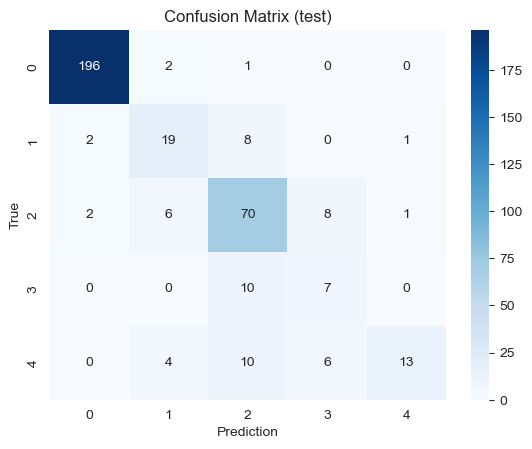

In [3]:
import torch
import os
import logging
import timm
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from src.dataset import FundusDataset, get_transform, get_soft_balanced_sampler
from src.loss import FocalLoss
from src.model import EfficientNetB4_CBAM
from src.optimizer import optimizer
from sklearn.metrics import classification_report, confusion_matrix

from src.training import training


g = torch.Generator()
g.manual_seed(0)

# ---- Switch this to "test" or "valid" ----
SPLIT = "test"

eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/APTOS-2019"
result_dir = os.path.join(eval_dir, "results")
data_dir = "D:/DeepLearning/Dataset/APTOS-2019"
train_img_dir = os.path.join(data_dir, "train_images")
valid_img_dir = os.path.join(data_dir, "valid_images")
test_img_dir = os.path.join(data_dir, "test_images")
train_csv_dir = os.path.join(data_dir, "train.csv")
valid_csv_dir = os.path.join(data_dir, "valid.csv")
test_csv_dir = os.path.join(data_dir, "test.csv")
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
log_dir = os.path.join(eval_dir, "logs")

# Resolve paths based on SPLIT
if SPLIT == "test":
    eval_csv_dir = test_csv_dir
    eval_img_dir = test_img_dir
elif SPLIT == "valid":
    eval_csv_dir = valid_csv_dir
    eval_img_dir = valid_img_dir
else:
    raise ValueError(f"SPLIT must be 'test' or 'valid', got {SPLIT}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
model = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.1, classifier_dropout_rate=0.5, num_class=5)
model = model.to(device)

checkpoint = torch.load(os.path.join(chkpt_dir, "epoch53_validF1_0.7368.pth"))
model.load_state_dict(checkpoint["model_state"])

eval_df = pd.read_csv(eval_csv_dir)
eval_df['diagnosis'] = eval_df['diagnosis'].astype(int)
train_transform, valid_transform = get_transform(380)
eval_dataset = FundusDataset(eval_df, img_dir=eval_img_dir, transform=valid_transform)
eval_loader = DataLoader(
    eval_dataset,
    batch_size=48,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    prefetch_factor=2,
    generator=g,
)

model.eval()
total_eval_loss = 0.0
eval_corrects = 0
all_eval_preds = []
all_eval_labels = []

with torch.no_grad():
    for i, (images, labels) in enumerate(eval_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        _, preds = torch.max(outputs, dim=1)
        eval_corrects += torch.sum(preds == labels.data)
        all_eval_preds.extend(preds.cpu().numpy())
        all_eval_labels.extend(labels.cpu().numpy())

class_names = ['0', '1', '2', '3', '4']
report = classification_report(all_eval_labels, all_eval_preds, target_names=class_names, output_dict=True)
print(report)
report_df = pd.DataFrame(report).transpose()
#report_df.to_csv(os.path.join(result_dir, f"classification_report_{SPLIT}.csv"))

cm = confusion_matrix(all_eval_labels, all_eval_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediction")
plt.ylabel("True")
plt.title(f"Confusion Matrix ({SPLIT})")
#plt.savefig(os.path.join(result_dir, f"confusion_matrix_{SPLIT}.png"), dpi=300)
plt.show()


=== 5-class classification report (valid) ===
              precision    recall  f1-score     support
0              0.994152  0.988372  0.991254  172.000000
1              0.720930  0.775000  0.746988   40.000000
2              0.790000  0.759615  0.774510  104.000000
3              0.500000  0.590909  0.541667   22.000000
4              0.653846  0.607143  0.629630   28.000000
accuracy       0.846995  0.846995  0.846995    0.846995
macro avg      0.731786  0.744208  0.736810  366.000000
weighted avg   0.850544  0.846995  0.848280  366.000000

=== Binary (No DR vs DR) classification report (valid) ===
              precision    recall  f1-score     support
No DR          0.994152  0.988372  0.991254  172.000000
DR             0.989744  0.994845  0.992288  194.000000
accuracy       0.991803  0.991803  0.991803    0.991803
macro avg      0.991948  0.991609  0.991771  366.000000
weighted avg   0.991815  0.991803  0.991802  366.000000

=== 5-class classification report (test) ===
       

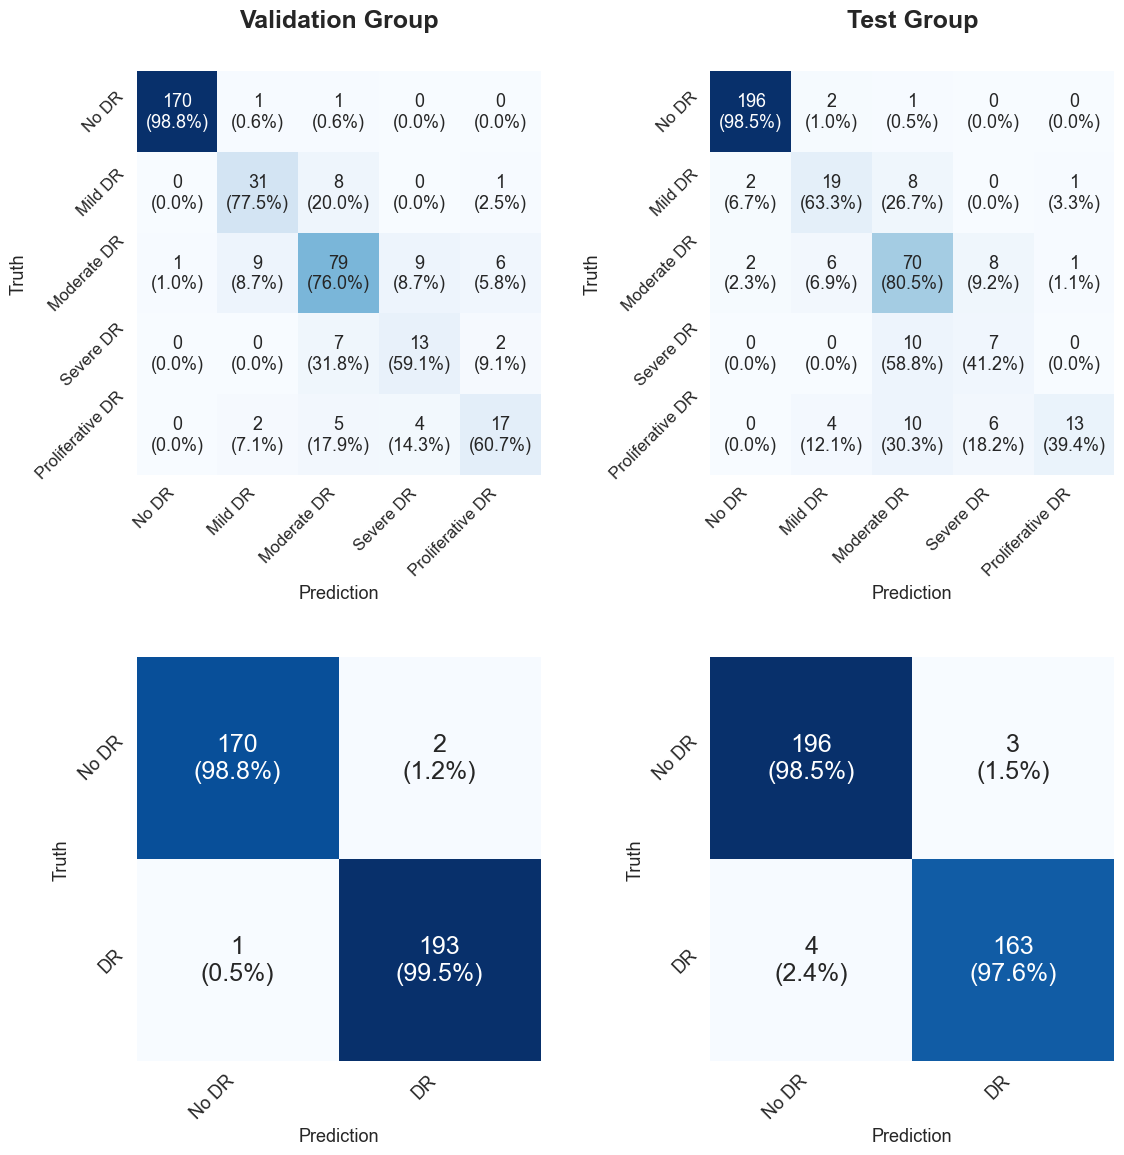

In [6]:
import torch
import os
import logging
import timm
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from src.dataset import FundusDataset, get_transform, get_soft_balanced_sampler
from src.loss import FocalLoss
from src.model import EfficientNetB4_CBAM
from src.optimizer import optimizer
from sklearn.metrics import classification_report, confusion_matrix

from src.training import training


g = torch.Generator()
g.manual_seed(0)

eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/APTOS-2019"
result_dir = os.path.join(eval_dir, "results")
data_dir = "D:/DeepLearning/Dataset/APTOS-2019"
train_img_dir = os.path.join(data_dir, "train_images")
valid_img_dir = os.path.join(data_dir, "valid_images")
test_img_dir = os.path.join(data_dir, "test_images")
train_csv_dir = os.path.join(data_dir, "train.csv")
valid_csv_dir = os.path.join(data_dir, "valid.csv")
test_csv_dir = os.path.join(data_dir, "test.csv")
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
log_dir = os.path.join(eval_dir, "logs")

os.makedirs(result_dir, exist_ok=True)

class_names = ['0', '1', '2', '3', '4']
class_names_full = ['No DR', 'Mild DR', 'Moderate DR', 'Severe DR', 'Proliferative DR']
binary_class_names = ['No DR', 'DR']

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
model = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.1, classifier_dropout_rate=0.5, num_class=5)
model = model.to(device)

checkpoint = torch.load(os.path.join(chkpt_dir, "epoch53_validF1_0.7368.pth"))
model.load_state_dict(checkpoint["model_state"])
model.eval()

_, valid_transform = get_transform(380)


def to_binary(labels):
    return np.array([0 if int(l) == 0 else 1 for l in labels])


def run_eval(split):
    """Run inference for a given split ('valid' or 'test') and return labels/preds."""
    if split == "test":
        csv_path, img_dir = test_csv_dir, test_img_dir
    elif split == "valid":
        csv_path, img_dir = valid_csv_dir, valid_img_dir
    else:
        raise ValueError(f"split must be 'test' or 'valid', got {split}")

    df = pd.read_csv(csv_path)
    df['diagnosis'] = df['diagnosis'].astype(int)
    dataset = FundusDataset(df, img_dir=img_dir, transform=valid_transform)
    loader = DataLoader(
        dataset,
        batch_size=48,
        shuffle=False,
        num_workers=8,
        pin_memory=True,
        prefetch_factor=2,
        generator=g,
    )

    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(images)
            _, preds = torch.max(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_labels), np.array(all_preds)


# ---- Run both splits ----
results = {}
for split in ["valid", "test"]:
    labels, preds = run_eval(split)

    report = classification_report(labels, preds, target_names=class_names, output_dict=True)
    report_df = pd.DataFrame(report).transpose()
    print(f"\n=== 5-class classification report ({split}) ===")
    print(report_df)
    # report_df.to_csv(os.path.join(result_dir, f"classification_report_{split}.csv"))

    bin_labels, bin_preds = to_binary(labels), to_binary(preds)
    binary_report = classification_report(bin_labels, bin_preds, target_names=binary_class_names, output_dict=True)
    binary_report_df = pd.DataFrame(binary_report).transpose()
    print(f"\n=== Binary (No DR vs DR) classification report ({split}) ===")
    print(binary_report_df)
    # binary_report_df.to_csv(os.path.join(result_dir, f"classification_report_binary_{split}.csv"))

    results[split] = {
        "labels": labels, "preds": preds,
        "bin_labels": bin_labels, "bin_preds": bin_preds,
    }


def plot_cm(ax, labels, preds, class_labels, annot_fontsize=18, tick_fontsize=13):
    """Plot a confusion matrix with counts + row-normalized percentages."""
    cm = confusion_matrix(labels, preds)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    annot = np.empty_like(cm).astype(object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)"

    sns.heatmap(
        cm,
        annot=annot,
        fmt="",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        cbar=False,
        ax=ax,
        square=True,
        annot_kws={"fontsize": annot_fontsize},
    )

    # Slanted tick labels so the full DR-grade names don't overlap
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=tick_fontsize)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=45, ha="right", fontsize=tick_fontsize)

    # Each matrix now carries its own axis labels
    ax.set_xlabel("Prediction", fontsize=13)
    ax.set_ylabel("Truth", fontsize=13)


# ---- 2x2 grid: top row = 5-class, bottom row = binary (DR vs No DR) ----
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# Top row (5-class): larger than before, but still smaller than the bottom row
plot_cm(axes[0, 0], results["valid"]["labels"], results["valid"]["preds"], class_names_full,
        annot_fontsize=13, tick_fontsize=12)
plot_cm(axes[0, 1], results["test"]["labels"], results["test"]["preds"], class_names_full,
        annot_fontsize=13, tick_fontsize=12)

# Bottom row (binary): unchanged
plot_cm(axes[1, 0], results["valid"]["bin_labels"], results["valid"]["bin_preds"], binary_class_names,
        annot_fontsize=18, tick_fontsize=13)
plot_cm(axes[1, 1], results["test"]["bin_labels"], results["test"]["bin_preds"], binary_class_names,
        annot_fontsize=18, tick_fontsize=13)

plt.tight_layout(rect=[0.03, 0.03, 1, 0.95])
fig.subplots_adjust(hspace=0.45)   # increased gap between top and bottom rows

fig.canvas.draw()  # ensure axes positions are finalized before reading them
pos_left = axes[0, 0].get_position()
pos_right = axes[0, 1].get_position()

fig.text((pos_left.x0 + pos_left.x1) / 2, 0.97, "Validation Group",
          ha="center", va="bottom", fontsize=18, fontweight="bold")
fig.text((pos_right.x0 + pos_right.x1) / 2, 0.97, "Test Group",
          ha="center", va="bottom", fontsize=18, fontweight="bold")

# ---- Save the figure ----
plt.savefig(os.path.join(result_dir, "confusion_matrix_grid.pdf"), bbox_inches="tight")
plt.show()

{'0': {'precision': 0.9941520467836257, 'recall': 0.9883720930232558, 'f1-score': 0.9912536443148688, 'support': 172.0}, '1': {'precision': 0.7209302325581395, 'recall': 0.775, 'f1-score': 0.7469879518072289, 'support': 40.0}, '2': {'precision': 0.79, 'recall': 0.7596153846153846, 'f1-score': 0.7745098039215687, 'support': 104.0}, '3': {'precision': 0.5, 'recall': 0.5909090909090909, 'f1-score': 0.5416666666666666, 'support': 22.0}, '4': {'precision': 0.6538461538461539, 'recall': 0.6071428571428571, 'f1-score': 0.6296296296296297, 'support': 28.0}, 'accuracy': 0.8469945355191257, 'macro avg': {'precision': 0.7317856866375838, 'recall': 0.7442078851381176, 'f1-score': 0.7368095392679925, 'support': 366.0}, 'weighted avg': {'precision': 0.8505438624502774, 'recall': 0.8469945355191257, 'f1-score': 0.8482799475371203, 'support': 366.0}}
{'No DR': {'precision': 0.9941520467836257, 'recall': 0.9883720930232558, 'f1-score': 0.9912536443148688, 'support': 172.0}, 'DR': {'precision': 0.989743

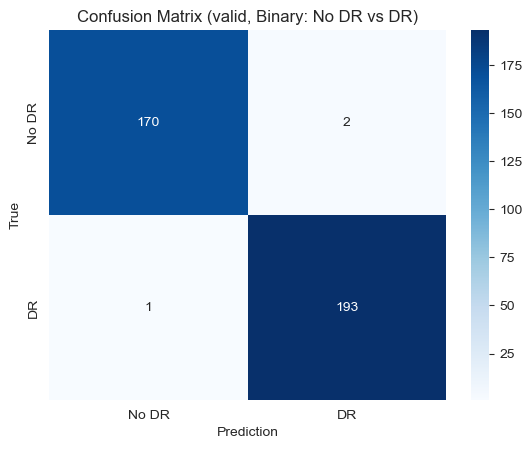

In [2]:
import torch
import os
import logging
import timm
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from src.dataset import FundusDataset, get_transform, get_soft_balanced_sampler
from src.loss import FocalLoss
from src.model import EfficientNetB4_CBAM
from src.optimizer import optimizer
from sklearn.metrics import classification_report, confusion_matrix

from src.training import training


g = torch.Generator()
g.manual_seed(0)

# ---- Switch this to "test" or "valid" ----
SPLIT = "valid"

eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/APTOS-2019"
result_dir = os.path.join(eval_dir, "results")
data_dir = "D:/DeepLearning/Dataset/APTOS-2019"
train_img_dir = os.path.join(data_dir, "train_images")
valid_img_dir = os.path.join(data_dir, "valid_images")
test_img_dir = os.path.join(data_dir, "test_images")
train_csv_dir = os.path.join(data_dir, "train.csv")
valid_csv_dir = os.path.join(data_dir, "valid.csv")
test_csv_dir = os.path.join(data_dir, "test.csv")
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
log_dir = os.path.join(eval_dir, "logs")

# Resolve paths based on SPLIT
if SPLIT == "test":
    eval_csv_dir = test_csv_dir
    eval_img_dir = test_img_dir
elif SPLIT == "valid":
    eval_csv_dir = valid_csv_dir
    eval_img_dir = valid_img_dir
else:
    raise ValueError(f"SPLIT must be 'test' or 'valid', got {SPLIT}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
model = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.1, classifier_dropout_rate=0.5, num_class=5)
model = model.to(device)

checkpoint = torch.load(os.path.join(chkpt_dir, "epoch53_validF1_0.7368.pth"))
model.load_state_dict(checkpoint["model_state"])

eval_df = pd.read_csv(eval_csv_dir)
eval_df['diagnosis'] = eval_df['diagnosis'].astype(int)
train_transform, valid_transform = get_transform(380)
eval_dataset = FundusDataset(eval_df, img_dir=eval_img_dir, transform=valid_transform)
eval_loader = DataLoader(
    eval_dataset,
    batch_size=48,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    prefetch_factor=2,
    generator=g,
)

model.eval()
total_eval_loss = 0.0
eval_corrects = 0
all_eval_preds = []
all_eval_labels = []

with torch.no_grad():
    for i, (images, labels) in enumerate(eval_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        _, preds = torch.max(outputs, dim=1)
        eval_corrects += torch.sum(preds == labels.data)
        all_eval_preds.extend(preds.cpu().numpy())
        all_eval_labels.extend(labels.cpu().numpy())

# ---- Original 5-class report (optional, kept for reference) ----
class_names = ['0', '1', '2', '3', '4']
report = classification_report(all_eval_labels, all_eval_preds, target_names=class_names, output_dict=True)
print(report)
report_df = pd.DataFrame(report).transpose()
#report_df.to_csv(os.path.join(result_dir, f"classification_report_{SPLIT}.csv"))

# ---- Collapse into binary: 0 = No DR, 1-4 = DR ----
def to_binary(labels):
    return [0 if int(l) == 0 else 1 for l in labels]

binary_preds = to_binary(all_eval_preds)
binary_labels = to_binary(all_eval_labels)

binary_class_names = ['No DR', 'DR']

binary_report = classification_report(
    binary_labels, binary_preds,
    target_names=binary_class_names,
    output_dict=True
)
print(binary_report)
binary_report_df = pd.DataFrame(binary_report).transpose()
#binary_report_df.to_csv(os.path.join(result_dir, f"classification_report_binary_{SPLIT}.csv"))

# ---- 2x2 Confusion Matrix ----
cm_binary = confusion_matrix(binary_labels, binary_preds)
sns.heatmap(cm_binary, annot=True, fmt="d", cmap="Blues",
            xticklabels=binary_class_names, yticklabels=binary_class_names)
plt.xlabel("Prediction")
plt.ylabel("True")
plt.title(f"Confusion Matrix ({SPLIT}, Binary: No DR vs DR)")
#plt.savefig(os.path.join(result_dir, f"confusion_matrix_binary_{SPLIT}.png"), dpi=300)
plt.show()